<a href="https://colab.research.google.com/github/Pradeep-Kumar-Panga/DecodingComplexities/blob/main/SVD_LoRA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📐 SVD → LoRA: The Linear Algebra Behind Efficient Fine-Tuning

**@DecodingComplexities** | [YouTube](https://www.youtube.com/@DecodingComplexities), [Blog](https://www.pradeeppanga.com)

---

Fine-tuning a large language model sounds simple: update the weights until it gets better at your task. But a model like LLaMA-7B has 7 billion parameters. Updating all of them requires storing gradients, optimizer states, and weight copies — a memory cost that puts full fine-tuning out of reach for most practitioners.

LoRA (Low-Rank Adaptation) sidesteps this entirely. Instead of updating the full weight matrix $W$, it freezes $W$ and learns a small correction: $\Delta W = BA$, where $B$ and $A$ are thin matrices. At rank $r = 8$, this is a **48× reduction** in trainable parameters for a 768-dimensional layer — with almost no loss in task performance.

But why does this work? Because of a mathematical fact that was proved in 1936: the best rank-$r$ approximation to any matrix is given by its top $r$ singular triplets — the Singular Value Decomposition. And empirically, the fine-tuning update $\Delta W$ turns out to be intrinsically low-rank, even when the pretrained weight $W$ is not.

This notebook builds that argument from first principles, using a real transformer (DistilBERT) so every claim is grounded in actual numbers.

**In this notebook, we build and understand:**

1. **SVD as geometry** — not just a formula; a decomposition into rotate · scale · rotate  
2. **Singular value spectra of real weights** — rapid decay means low intrinsic rank  
3. **The Eckart–Young theorem** — why truncated SVD is the *provably optimal* low-rank approximation  
4. **The LoRA mechanism** — how $\Delta W = BA$ enforces rank, initialises to zero, and merges at inference  
5. **Choosing rank r** — reading the elbow in the $\sigma$ spectrum of $\Delta W$  
6. **Putting it all together** — a full implementation and a 3-panel synthesis connecting SVD theory to parameter-efficient fine-tuning  

---
## Section 1 — SVD: Rotation · Scale · Rotation

A matrix $M \in \mathbb{R}^{m \times n}$ transforms vectors. SVD makes that transformation explicit:

$$M = U \Sigma V^\top$$

| Factor | Shape | Meaning |
|---|---|---|
| $V^\top$ | $n \times n$ | Rotation — aligns input to a clean basis |
| $\Sigma$ | $m \times n$ (diagonal) | Scale — stretches each basis direction by a singular value |
| $U$ | $m \times m$ | Rotation — maps into output space |

The singular values $\sigma_1 \geq \sigma_2 \geq \ldots \geq 0$ tell you **how much each direction matters**.


In [1]:
# Setup
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyArrowPatch
import warnings
warnings.filterwarnings('ignore')

# Dark theme for all plots
plt.rcParams.update({
    'figure.facecolor':  '#1e1e1e',
    'axes.facecolor':    '#2a2a2a',
    'axes.edgecolor':    '#555555',
    'axes.labelcolor':   '#cccccc',
    'text.color':        '#cccccc',
    'xtick.color':       '#aaaaaa',
    'ytick.color':       '#aaaaaa',
    'grid.color':        '#404040',
    'grid.linestyle':    '--',
    'lines.linewidth':   2.0,
    'font.family':       'monospace',
    'font.size':         13,
    'font.weight':       'bold',
    'axes.titlesize':    15,
    'axes.titleweight':  'bold',
    'axes.labelsize':    13,
    'axes.labelweight':  'bold',
    'xtick.labelsize':   12,
    'ytick.labelsize':   12,
    'legend.fontsize':   12,
    'figure.titlesize':  16,
})

PURPLE  = '#7B61FF'
TEAL    = '#00A88A'
CORAL   = '#D94040'
AMBER   = '#FFAA00'
BLACK   = '#E0E0E0'
MUTED   = '#888888'

print("Setup complete.")


Setup complete.


### 1a — Understanding SVD & Visualising as a geometric transformation

We take a unit circle, apply a 2×2 matrix, and watch SVD decompose the transformation  
into: **rotate → stretch → rotate**.  

The ellipse you see after the full transform is the signature of the matrix.

**What the code does:**  
- Constructs a 2×2 matrix `M = [[3, 1], [0.5, 2]]` and computes its full SVD.  
- Generates 300 points on the unit circle, then passes them through each stage of the decomposition: $V^\top x$ (first rotation), $\Sigma V^\top x$ (scaling), $U \Sigma V^\top x$ (second rotation → output).  
- Plots all 4 stages side by side so you can see exactly what each factor does to the shape.  
- Annotates the final panel with arrows marking the two principal output directions, labelled with their singular values $\sigma_1$ and $\sigma_2$.  

**What to look for:**  
The unit circle stays a circle after a pure rotation ($V^\top$), becomes an axis-aligned ellipse after scaling ($\Sigma$), then gets rotated into its final orientation by $U$. The aspect ratio of the ellipse equals $\sigma_1 / \sigma_2$ — a measure of how "directional" the matrix is.


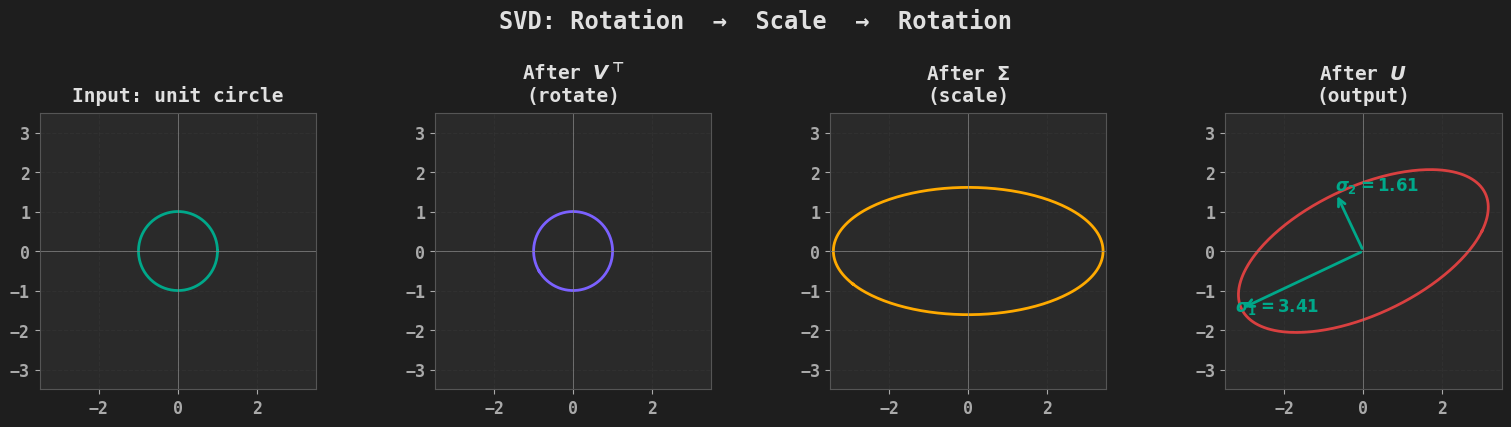

Singular values: σ₁ = 3.4139,  σ₂ = 1.6111
Ratio σ₁/σ₂ = 2.12  — most 'work' is in the first direction


In [2]:
# Visualise SVD on a unit circle
np.random.seed(42)

# A simple 2×2 matrix with clear structure
M = np.array([[3.0, 1.0],
              [0.5, 2.0]])

U, s, Vt = np.linalg.svd(M)
Sigma = np.diag(s)

# Unit circle points
theta = np.linspace(0, 2 * np.pi, 300)
circle = np.vstack([np.cos(theta), np.sin(theta)])   # 2 × 300

# Intermediate stages
stage1 = Vt @ circle            # after first rotation  (Vᵀ x)
stage2 = Sigma @ stage1         # after scaling         (Σ Vᵀ x)
stage3 = U @ stage2             # after second rotation (U Σ Vᵀ x)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle("SVD: Rotation  →  Scale  →  Rotation", fontsize=17, fontweight='bold',
             color=BLACK, y=1.02)

stages = [
    (circle,  "Input: unit circle",    TEAL),
    (stage1,  "After $V^\\top$\n(rotate)", PURPLE),
    (stage2,  "After $\\Sigma$\n(scale)",  AMBER),
    (stage3,  "After $U$\n(output)",   CORAL),
]

for ax, (pts, title, color) in zip(axes, stages):
    ax.plot(pts[0], pts[1], color=color, lw=2)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=14, fontweight='bold', color=BLACK, pad=8)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
    ax.axhline(0, color=MUTED, lw=0.5)
    ax.axvline(0, color=MUTED, lw=0.5)
    ax.grid(True, alpha=0.3)
    # Mark singular value directions on the output
    if title.startswith("After $U$"):
        for i in range(2):
            vec = s[i] * U[:, i]
            ax.annotate("", xy=vec, xytext=(0, 0),
                        arrowprops=dict(arrowstyle='->', color=TEAL, lw=2))
            ax.text(vec[0]*1.05, vec[1]*1.05,
                    f"$\\sigma_{i+1}={s[i]:.2f}$", color=TEAL, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()
print(f"Singular values: σ₁ = {s[0]:.4f},  σ₂ = {s[1]:.4f}")
print(f"Ratio σ₁/σ₂ = {s[0]/s[1]:.2f}  — most 'work' is in the first direction")


---
## Section 2 — Singular Value Spectrum of Real Transformer Weights

We load a real pre-trained transformer (DistilBERT, ~66M params — small enough to run on CPU)  
and inspect the singular value spectrum of its attention weight matrices.

The pattern we expect: **rapid decay**. A few large values, then a long tail near zero.

**What the code does:**

1. **Load & extract weights** — downloads `distilbert-base-uncased` (≈ 260 MB, cached after first run), iterates all named parameters, and collects every 2D attention projection matrix matching `q_lin`, `k_lin`, `v_lin`, or `out_lin` — 24 matrices of shape 768 × 768 (one query, key, value, and output projection per attention head group, across 6 transformer layers).

2. **Singular value spectra** — for each of the first 6 matrices, computes the full SVD, normalises the singular values to $[0, 1]$ (dividing by $\sigma_1$), plots the decay curve, and marks the **elbow** — the index where $\sigma_i / \sigma_1$ first drops below 0.1. A sharp elbow means a few directions dominate.

3. **Cumulative energy** — for every matrix, computes the cumulative fraction of total Frobenius energy: $\text{energy}(r) = \sum_{i=1}^r \sigma_i^2 \,/\, \sum_{i=1}^n \sigma_i^2$. Draws threshold lines at 90%, 95%, and 99%, annotated with the average rank needed to reach each threshold.

**What to look for:**  
All 24 curves behave almost identically — rapid early rise, then a plateau. This is the empirical evidence that trained transformer weights are *intrinsically* low-rank, which is precisely the assumption LoRA exploits.


In [3]:
# Install / import transformers (lightweight, CPU-only)
try:
    from transformers import AutoModel
    import torch
    print("transformers already available")
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "transformers", "torch", "--quiet"])
    from transformers import AutoModel
    import torch
    print("Installed transformers")

transformers already available


In [4]:
# Load DistilBERT and extract weight matrices
model = AutoModel.from_pretrained('distilbert-base-uncased')
model.eval()

# Collect all attention query/key/value projection matrices (2D weights only, not biases)
weight_matrices = {}
for name, param in model.named_parameters():
    if any(k in name for k in ['q_lin', 'k_lin', 'v_lin', 'out_lin']) and param.ndim == 2:
        weight_matrices[name] = param.detach().numpy()

print(f"\nFound {len(weight_matrices)} attention projection matrices")
for name, W in list(weight_matrices.items()):
    print(f"  {name:50s}  shape: {W.shape}")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Found 24 attention projection matrices
  transformer.layer.0.attention.q_lin.weight          shape: (768, 768)
  transformer.layer.0.attention.k_lin.weight          shape: (768, 768)
  transformer.layer.0.attention.v_lin.weight          shape: (768, 768)
  transformer.layer.0.attention.out_lin.weight        shape: (768, 768)
  transformer.layer.1.attention.q_lin.weight          shape: (768, 768)
  transformer.layer.1.attention.k_lin.weight          shape: (768, 768)
  transformer.layer.1.attention.v_lin.weight          shape: (768, 768)
  transformer.layer.1.attention.out_lin.weight        shape: (768, 768)
  transformer.layer.2.attention.q_lin.weight          shape: (768, 768)
  transformer.layer.2.attention.k_lin.weight          shape: (768, 768)
  transformer.layer.2.attention.v_lin.weight          shape: (768, 768)
  transformer.layer.2.attention.out_lin.weight        shape: (768, 768)
  transformer.layer.3.attention.q_lin.weight          shape: (768, 768)
  transformer.layer.3.at

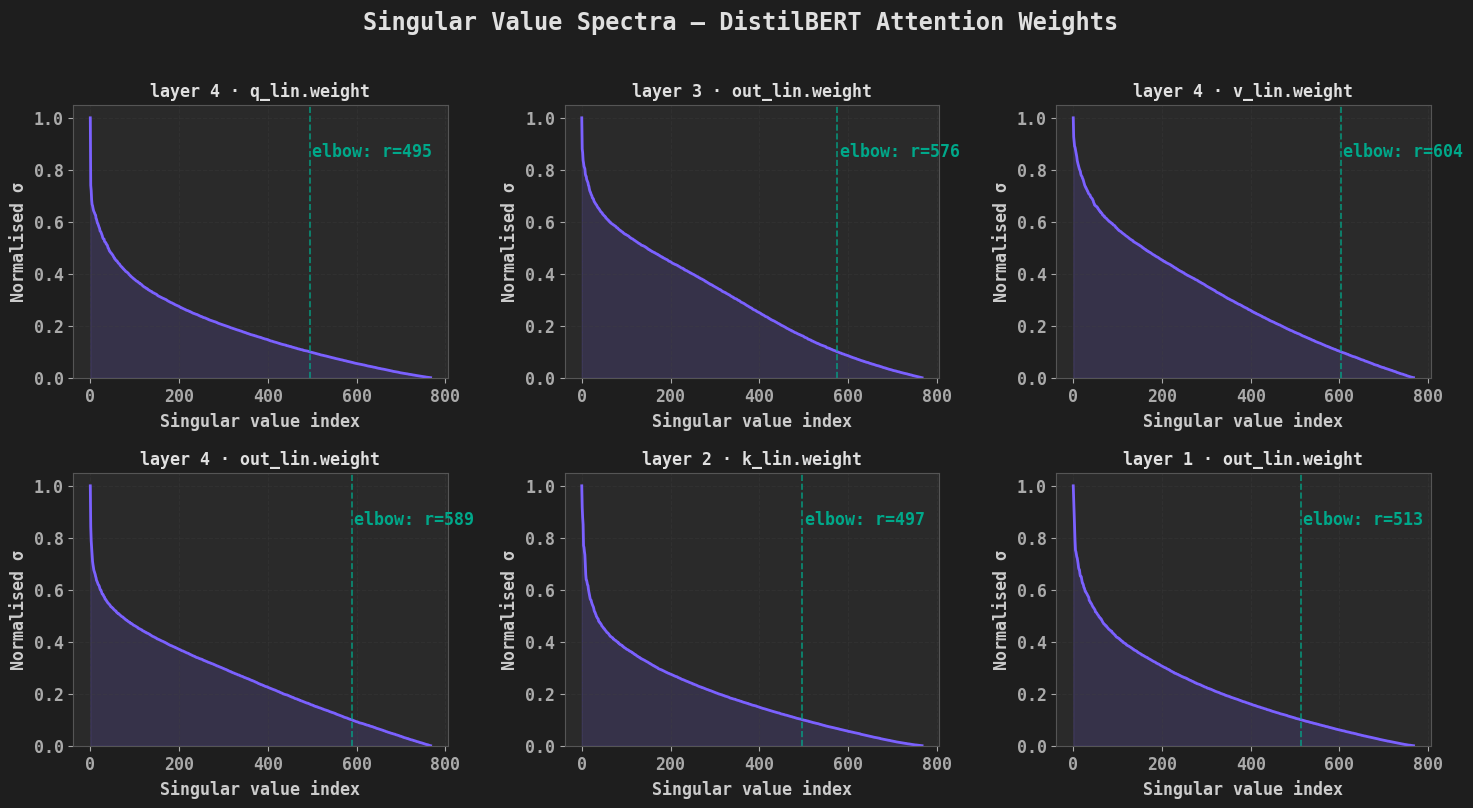


Key observation: in every layer, singular values decay rapidly.
Most of the 'work' is concentrated in a small number of directions.


In [5]:
# Plot singular value spectra for attention layers
# Pick 6 matrices from different layers for variety
rng = np.random.default_rng(42)
all_items = list(weight_matrices.items())
rng.shuffle(all_items)
selected = all_items[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle("Singular Value Spectra — DistilBERT Attention Weights",
             fontsize=17, fontweight='bold', color=BLACK, y=1.01)

for ax, (name, W) in zip(axes.flat, selected):
    U_, s_, Vt_ = np.linalg.svd(W, full_matrices=False)
    rank = W.shape[1]

    # Normalise so curves are comparable
    s_norm = s_ / s_[0]

    ax.plot(s_norm, color=PURPLE, lw=2)
    ax.fill_between(range(len(s_norm)), s_norm, alpha=0.15, color=PURPLE)

    # Mark the "elbow" — where normalised value drops below 0.1
    elbow = np.argmax(s_norm < 0.1)
    if elbow > 0:
        ax.axvline(elbow, color=TEAL, lw=1.2, linestyle='--', alpha=0.8)
        ax.text(elbow + 5, 0.85, f"elbow: r={elbow}",
                color=TEAL, fontsize=12, fontweight='bold')

    short_name = name.split('.')[-2] + '.' + name.split('.')[-1]
    layer_num  = [p for p in name.split('.') if p.isdigit()]
    layer_str  = f"layer {layer_num[0]}" if layer_num else ""
    ax.set_title(f"{layer_str} · {short_name}", fontsize=12, fontweight='bold', color=BLACK)
    ax.set_xlabel("Singular value index", fontsize=12)
    ax.set_ylabel("Normalised σ", fontsize=12)
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print("\nKey observation: in every layer, singular values decay rapidly.")
print("Most of the 'work' is concentrated in a small number of directions.")

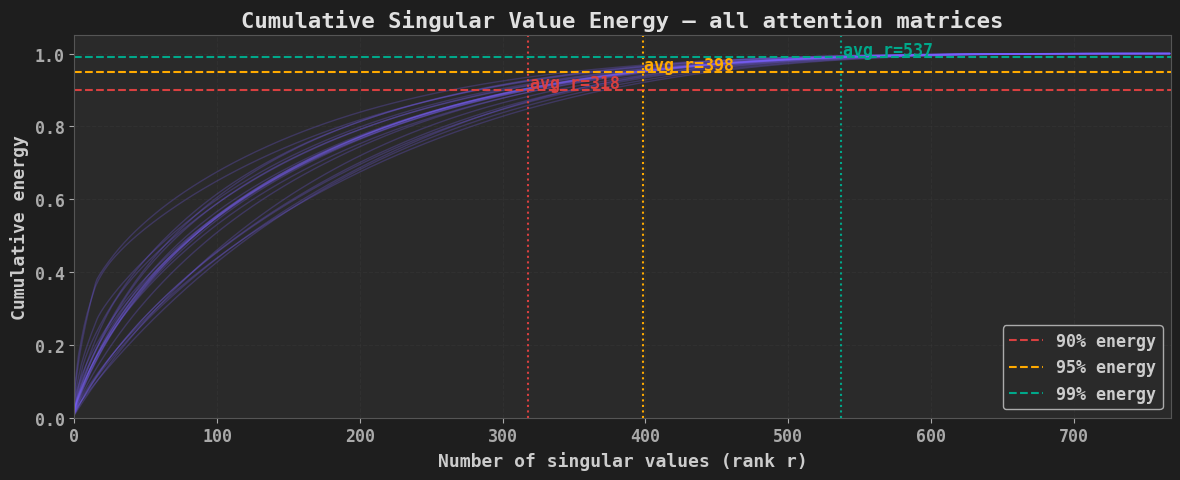


── How many singular values capture X% of the energy? ──
  90%  →  avg r = 318.3,  min = 265,  max = 373, percentage of full rank = 41.4%
  95%  →  avg r = 398.2,  min = 350,  max = 449, percentage of full rank = 51.9%
  99%  →  avg r = 537.9,  min = 504,  max = 576, percentage of full rank = 70.0%

Full rank of each matrix: 768
→ 99% energy captured with avg r ≈ 537.9 (70.0% of full rank)


In [6]:
# Cumulative explained 'energy'
# How many singular values do you need to capture 90%, 95%, 99% of the matrix?

thresholds = {0.90: CORAL, 0.95: AMBER, 0.99: TEAL}
r_stats = {t: [] for t in thresholds}

fig, ax = plt.subplots(figsize=(12, 5))
ax.set_title("Cumulative Singular Value Energy — all attention matrices",
             color=BLACK, fontsize=16, fontweight='bold')

for name, W in weight_matrices.items():
    _, s_, _ = np.linalg.svd(W, full_matrices=False)
    energy = np.cumsum(s_**2) / np.sum(s_**2)
    for t in thresholds:
        r_stats[t].append(np.searchsorted(energy, t) + 1)
    ax.plot(energy, color=PURPLE, alpha=0.25, lw=1)

# Determine x-axis limit to fit all labels inside the plot
r_max_overall = max(np.max(r_stats[t]) for t in thresholds)
xlim_max = list(weight_matrices.values())[0].shape[1]

# Threshold lines and labels
for t, color in thresholds.items():
    r_mean = int(np.mean(r_stats[t]))
    r_max  = np.max(r_stats[t])
    # Horizontal dashed: marks the energy threshold on the y-axis
    ax.axhline(t, color=color, lw=1.5, linestyle='--', label=f"{int(t*100)}% energy")
    # Vertical dotted: marks the avg rank needed on the x-axis (same color)
    ax.axvline(r_mean, color=color, lw=1.5, linestyle=':')
    ax.text(r_mean + 1, t + 0.005,
            f"avg r={r_mean}", color=color, fontsize=12, fontweight='bold')

ax.set_xlabel("Number of singular values (rank r)", fontsize=13)
ax.set_ylabel("Cumulative energy", fontsize=13)
ax.set_xlim(0, xlim_max)
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right', fontsize=12)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n── How many singular values capture X% of the energy? ──")
for t, color in thresholds.items():
    vals = r_stats[t]
    print(f"  {int(t*100)}%  →  avg r = {np.mean(vals):.1f},  "
          f"min = {np.min(vals)},  max = {np.max(vals)}, percentage of full rank = {np.mean(vals)/xlim_max*100:.1f}%")

full_rank = list(weight_matrices.values())[0].shape[1]
print(f"\nFull rank of each matrix: {full_rank}")
print(f"→ 99% energy captured with avg r ≈ {np.mean(r_stats[0.99]):.1f} "
      f"({np.mean(r_stats[0.99])/full_rank*100:.1f}% of full rank)")


---
## Section 3 — Low-Rank Approximation and the Eckart–Young Theorem

The rank-r approximation keeps only the top r singular triplets:

$$M \approx M_r = U_r \Sigma_r V_r^\top$$

**Eckart–Young (1936):** among all rank-r matrices, $M_r$ minimises both  
the Frobenius norm $\|M - M_r\|_F$ and the spectral norm $\|M - M_r\|_2$.  
In other words, truncated SVD is not just *a* low-rank approximation — it is the **provably optimal** one.

**What the code does:**

1. **Reconstruction heatmaps** — takes the first DistilBERT attention weight matrix $W_0$ (768 × 768), computes its full SVD, then rebuilds it at 6 ranks: `[1, 8, 64, 256, 512, 768]`. Produces two figures:
   - *Figure 1 (reconstructions):* heatmaps of $W_r$ on a shared colour scale — at low ranks the structure looks visibly different from the full matrix; by r=512 it is nearly indistinguishable.
   - *Figure 2 (residual error maps):* heatmaps of $|W_0 - W_r|$ on a shared colour scale anchored to the r=1 error — these make the rank differences obvious. At $r=1$ the error is large and bright; by $r=32$ the map is nearly black.

2. **Frobenius error vs rank (elbow curve)** — sweeps every rank from 1 to 768, computes the relative Frobenius error $\|W_0 - W_r\|_F / \|W_0\|_F$ at each, and plots the decay curve. Key ranks (4, 8, 16, 32) are annotated with their corresponding energy captured.

**What to look for:**  
At low ranks (e.g. r=1), the reconstruction looks visibly different from the full matrix — the single dominant direction is captured but the fine structure is gone. The error maps make this stark: r=1 is bright everywhere, dimming rapidly as rank increases, with most residual structure vanishing by r=32.

The elbow curve shows the same story: reconstruction error drops steeply at first, then flattens. **But — and this is crucial — LoRA does not use this elbow to pick r.** At r=8, W₀ reconstruction is still ~87% incomplete. That is expected and correct. LoRA uses r=8 because the fine-tuning *update* ΔW is empirically low-rank, even when W₀ is not. W₀'s σ spectrum motivates why the design works; it does not determine r. Section 5 makes this distinction explicit.


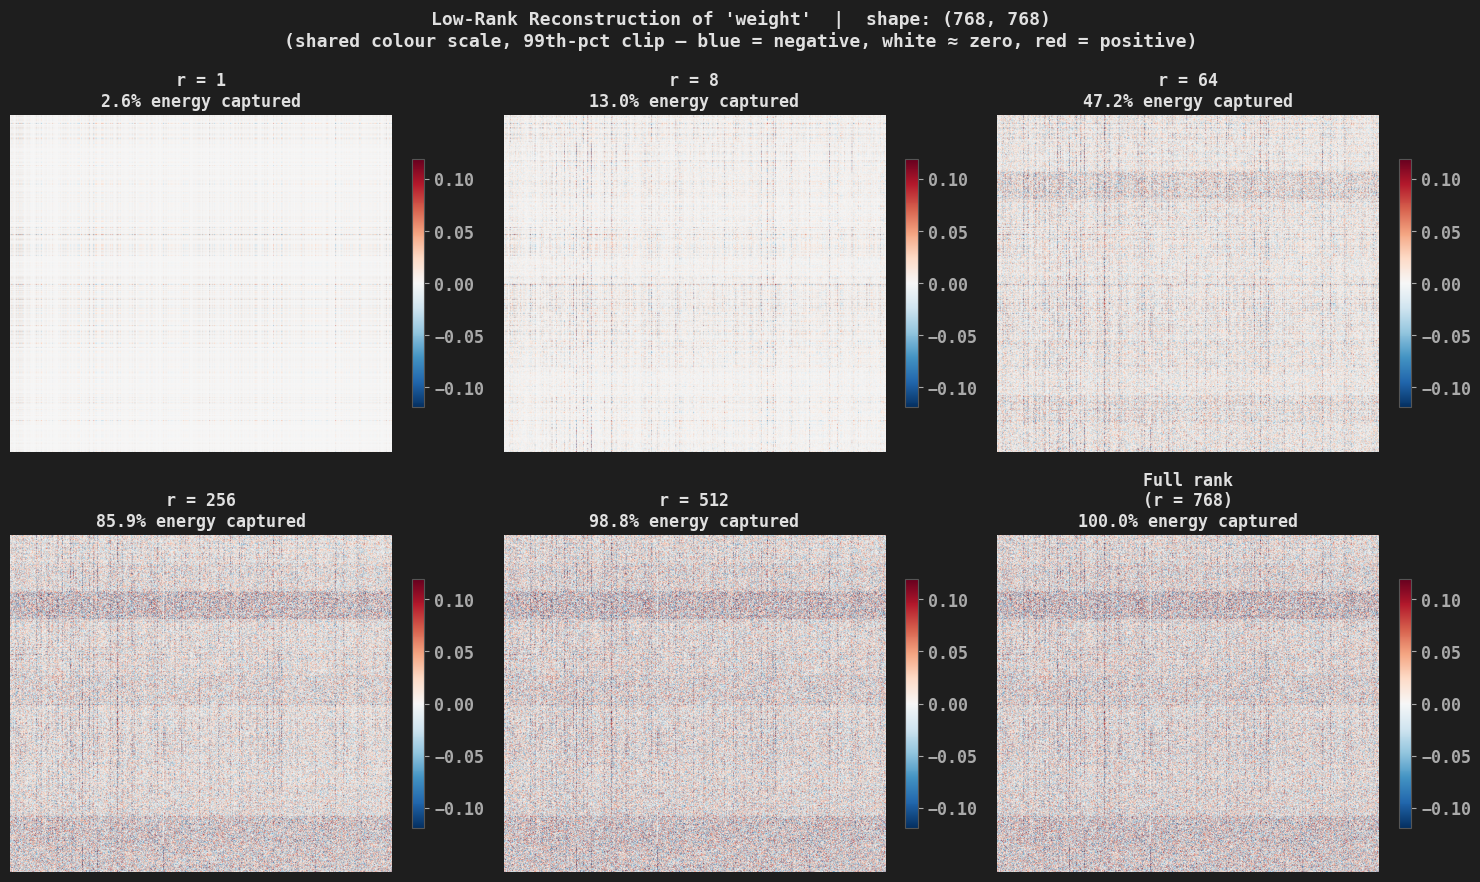

Note: at r=8, W₀ reconstruction is ~87% incomplete — and that is correct.
LoRA does NOT reconstruct W₀. It represents the fine-tuning update ΔW,
which is empirically low-rank even when W₀ is not. See Section 5.


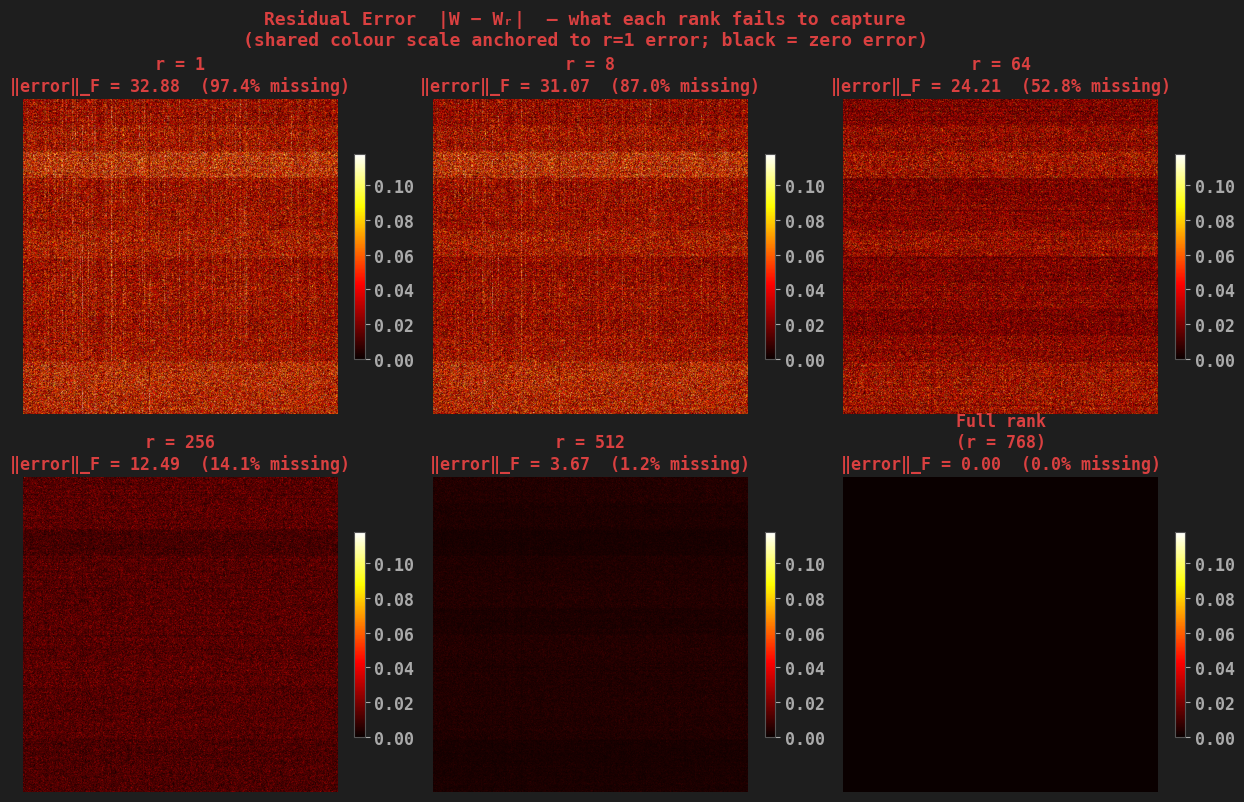

<Figure size 640x480 with 0 Axes>

In [7]:

# Low-rank reconstruction at increasing r
# Take the first attention query matrix
name0, W0 = list(weight_matrices.items())[0]
U0, s0, Vt0 = np.linalg.svd(W0, full_matrices=False)

ranks  = [1, 8, 64, 256, 512, W0.shape[1]]   # last entry = full rank
labels = [f"r = {r}" if r < W0.shape[1] else f"Full rank\n(r = {r})"
          for r in ranks]

frob_total = np.linalg.norm(W0, 'fro')**2

# Pre-compute reconstructions and error maps
reconstructions, error_maps, pct_list = [], [], []
for r in ranks:
    Wr = (U0[:, :r] * s0[:r]) @ Vt0[:r, :]
    err = np.linalg.norm(W0 - Wr, 'fro')**2
    reconstructions.append(Wr)
    error_maps.append(np.abs(W0 - Wr))
    pct_list.append((1 - err / frob_total) * 100)

# Figure 1: Reconstructions (shared color scale)
# At low ranks the reconstruction looks visibly different from the full matrix;
# the dominant direction is captured but the fine structure is lost. By r=512
# it is nearly indistinguishable. Compare with Figure 2 (error maps) for the
# full picture of what each rank fails to capture.
#
# Diverging colormap (RdBu_r): blue = negative, white = ~zero, red = positive.
# Use 99th-percentile clipping rather than the raw min/max: a small number of
# outlier weights would otherwise push the bulk of values (~0.01 scale) to
# appear white, making every subplot look blank.
sym = np.percentile(np.abs(W0), 99)

fig1, axes1 = plt.subplots(2, 3, figsize=(15, 9))
fig1.suptitle(
    f"Low-Rank Reconstruction of '{name0.split('.')[-1]}'  |  shape: {W0.shape}\n"
    f"(shared colour scale, 99th-pct clip — blue = negative, white ≈ zero, red = positive)",
    fontsize=13, fontweight='bold', color=BLACK)

for ax, Wr, lbl, pct in zip(axes1.flat, reconstructions, labels, pct_list):
    im = ax.imshow(Wr, cmap='RdBu_r', aspect='auto',
                   vmin=-sym, vmax=sym)
    ax.set_title(f"{lbl}\n{pct:.1f}% energy captured", fontsize=12, fontweight='bold', color=BLACK)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.03)

plt.tight_layout()
plt.show()
print("Note: at r=8, W₀ reconstruction is ~87% incomplete — and that is correct.")
print("LoRA does NOT reconstruct W₀. It represents the fine-tuning update ΔW,")
print("which is empirically low-rank even when W₀ is not. See Section 5.")

# Figure 2: Residual error maps — what each rank FAILS to capture
# Each subplot has its own colour scale; dark = near zero, bright = large error.
# Shared colour scale anchored to the r=1 error (the largest possible residual).
# This makes rank differences visible: r=1 is bright, r=32 is dim, r=768 is black.
# (Per-subplot auto-scaling would make every rank look equally bright — useless.)
shared_vmax = np.percentile(error_maps[0], 99)   # 99th-pct of r=1 error; clips outliers so bulk is visible

fig2, axes2 = plt.subplots(2, 3, figsize=(15, 9))
fig2.suptitle(
    "Residual Error  |W − Wᵣ|  — what each rank fails to capture\n"
    "(shared colour scale anchored to r=1 error; black = zero error)",
    fontsize=13, fontweight='bold', color=CORAL)

for ax, err_map, lbl, pct in zip(axes2.flat, error_maps, labels, pct_list):
    im = ax.imshow(err_map, cmap='hot', aspect='auto', vmin=0, vmax=shared_vmax)
    err_fro = np.sqrt(np.sum(err_map**2))
    ax.set_title(f"{lbl}\n‖error‖_F = {err_fro:.2f}  ({100-pct:.1f}% missing)",
                 fontsize=12, fontweight='bold', color=CORAL)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.03)

plt.show()
plt.tight_layout()

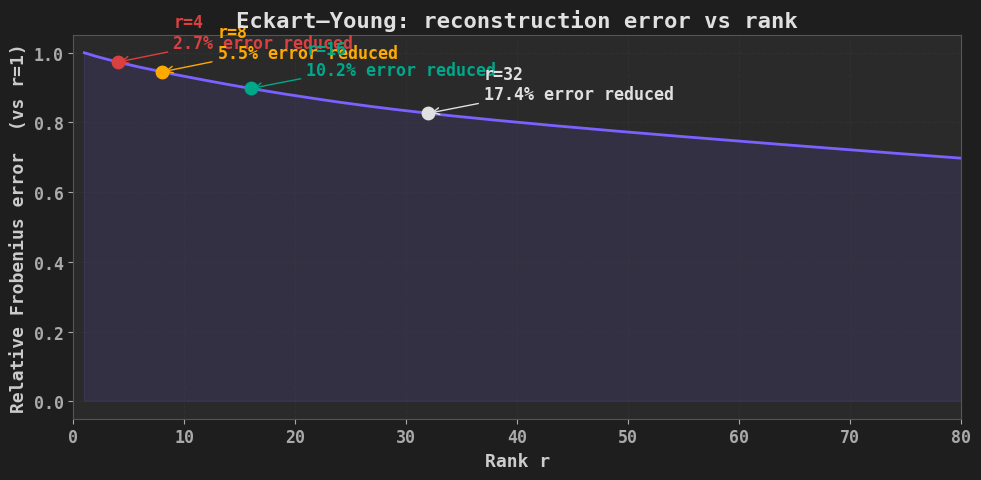

The curve flattens after the elbow. Beyond that point, adding more
singular values barely reduces error — you're fitting noise.


In [8]:
# Frobenius error vs rank — the elbow curve
r_range = np.arange(1, min(W0.shape) + 1)
frob_errors = []

for r in r_range:
    Wr = (U0[:, :r] * s0[:r]) @ Vt0[:r, :]
    frob_errors.append(np.linalg.norm(W0 - Wr, 'fro'))

frob_errors = np.array(frob_errors)
relative_errors = frob_errors / frob_errors[0]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(r_range, relative_errors, color=PURPLE, lw=2)
ax.fill_between(r_range, relative_errors, alpha=0.12, color=PURPLE)

# Highlight key ranks
for r_mark, color, label in [(4, CORAL, "r=4"), (8, AMBER, "r=8"),
                              (16, TEAL, "r=16"), (32, BLACK, "r=32")]:
    err_val = relative_errors[r_mark - 1]
    ax.scatter([r_mark], [err_val], s=80, color=color, zorder=5)
    ax.annotate(f"{label}\n{(1-err_val)*100:.1f}% error reduced",
                xy=(r_mark, err_val), xytext=(r_mark + 5, err_val + 0.04),
                color=color, fontsize=12, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color=color, lw=1))

ax.set_xlabel("Rank r", fontsize=13)
ax.set_ylabel("Relative Frobenius error  (vs r=1)", fontsize=13)
ax.set_title("Eckart–Young: reconstruction error vs rank", fontsize=16, fontweight='bold', color=BLACK)
ax.set_xlim(0, 80)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print("The curve flattens after the elbow. Beyond that point, adding more")
print("singular values barely reduces error — you're fitting noise.")


---
## Section 4 — The LoRA Mechanism: Parameterising ΔW = BA

**Full fine-tuning:** update all of $W \in \mathbb{R}^{d \times k}$ — costs $d \cdot k$ parameters.

**LoRA:** freeze $W$, learn $\Delta W = BA$ where $B \in \mathbb{R}^{d \times r}$, $A \in \mathbb{R}^{r \times k}$, $r \ll \min(d,k)$.

Forward pass: $h = Wx + BAx$

Key properties:
- $\text{rank}(BA) \leq r$ — enforced by construction (rank inequality)
- Initialisation: $A \sim \mathcal{N}(0, \sigma^2)$, $B = 0$ → $\Delta W = 0$ at step 0
- After training: merge back as $W' = W + BA$ — **zero inference overhead**

The trainable parameter count for one LoRA layer is $d \cdot r + r \cdot k = r(d + k)$, compared to $d \cdot k$ for full fine-tuning. The **reduction factor** is:

$$\frac{d \cdot k}{r(d + k)}$$

For a square matrix ($d = k$) this simplifies to $\frac{d}{2r}$ — so at $r=8$, $d=768$ you get a $\mathbf{48\times}$ reduction.

**What the code does:**

1. **Parameter table** — prints a formatted comparison for 4 real model configurations (DistilBERT, LLaMA-7B attention, LLaMA-7B FFN, LLaMA-70B attention) showing full parameter counts alongside LoRA counts and reduction factors at $r \in \{4, 8, 16, 32, 64\}$.

2. **Parameter savings plot** — uses $d = k = 4096$ (LLaMA-7B attention) to draw two panels:
   - *Left:* absolute parameter counts — full fine-tuning (flat line) vs LoRA (rising curve), with the gap shaded as savings. Key ranks are annotated.
   - *Right:* the reduction factor $dk \,/\, r(d+k)$ as a function of $r$, showing how quickly the benefit diminishes as $r$ grows.

**What to look for:**  
Even at $r=64$ — which may already be more than needed — LoRA uses only $\sim\!64\times$ fewer parameters than full fine-tuning for LLaMA-7B attention layers. At $r=8$ the saving exceeds $250\times$.


In [9]:
# Parameter count: full fine-tuning vs LoRA
configs = [
    # (d, k, model_name)
    (768,  768,  "DistilBERT attention"),
    (4096, 4096, "LLaMA-7B attention"),
    (4096, 11008,"LLaMA-7B FFN"),
    (8192, 8192, "LLaMA-70B attention"),
]
ranks = [4, 8, 16, 32, 64]

print(f"{'Layer':<20} {'Full params':>20}  "
      + "  ".join(f"{f'LoRA r={r:>2}':>14}" for r in ranks))
print("─" * 105)

for d, k, name in configs:
    full = d * k
    lora_counts = [d * r + r * k for r in ranks]
    reductions   = [full / lc for lc in lora_counts]
    row = f"{name:<20} {full:>20,}"
    for lc, red in zip(lora_counts, reductions):
        row += f"  {lc:>10,} ({red:.0f}x)"
    print(row)

print()
print("Observation: at r=8, LoRA reduces trainable parameters by ~250x")
print("for LLaMA-7B attention layers — while preserving the update direction.")

Layer                         Full params       LoRA r= 4       LoRA r= 8       LoRA r=16       LoRA r=32       LoRA r=64
─────────────────────────────────────────────────────────────────────────────────────────────────────────
DistilBERT attention              589,824       6,144 (96x)      12,288 (48x)      24,576 (24x)      49,152 (12x)      98,304 (6x)
LLaMA-7B attention             16,777,216      32,768 (512x)      65,536 (256x)     131,072 (128x)     262,144 (64x)     524,288 (32x)
LLaMA-7B FFN                   45,088,768      60,416 (746x)     120,832 (373x)     241,664 (187x)     483,328 (93x)     966,656 (47x)
LLaMA-70B attention            67,108,864      65,536 (1024x)     131,072 (512x)     262,144 (256x)     524,288 (128x)   1,048,576 (64x)

Observation: at r=8, LoRA reduces trainable parameters by ~250x
for LLaMA-7B attention layers — while preserving the update direction.


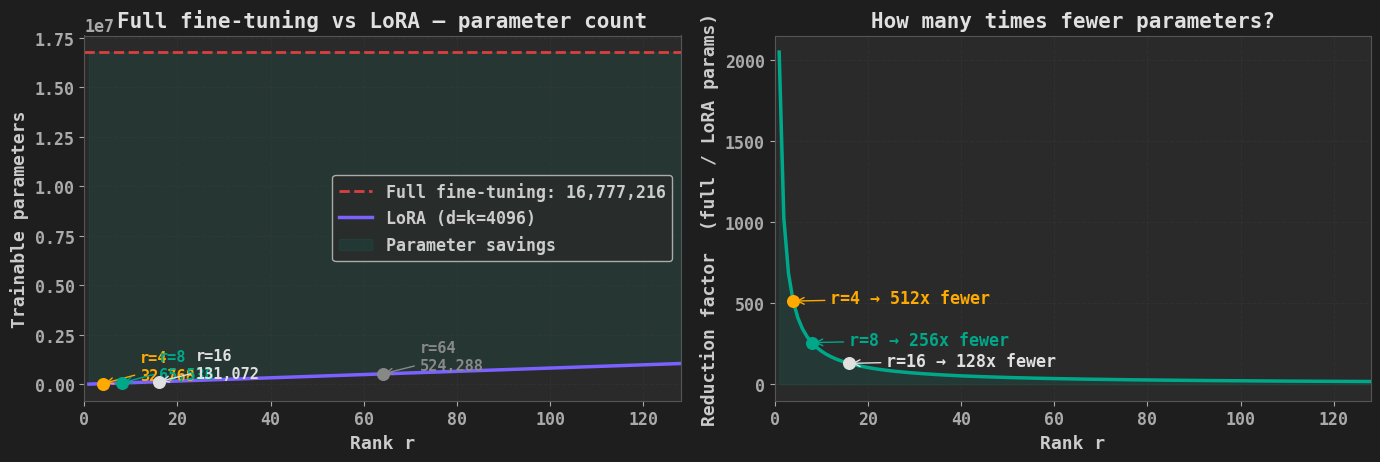

In [10]:
# Visualise the parameter savings
d, k = 4096, 4096   # LLaMA-7B attention
full_params = d * k

r_vals = np.arange(1, 129)
lora_params = d * r_vals + r_vals * k

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: absolute comparison
ax1.axhline(full_params, color=CORAL, lw=2, linestyle='--',
            label=f"Full fine-tuning: {full_params:,}")
ax1.plot(r_vals, lora_params, color=PURPLE, lw=2.5, label="LoRA (d=k=4096)")
ax1.fill_between(r_vals, lora_params, full_params, alpha=0.1, color=TEAL,
                 label="Parameter savings")

for r_mark, color in [(4, AMBER), (8, TEAL), (16, BLACK), (64, MUTED)]:
    lp = d * r_mark + r_mark * k
    ax1.scatter([r_mark], [lp], s=70, color=color, zorder=5)
    ax1.annotate(f"r={r_mark}\n{lp:,}", xy=(r_mark, lp),
                 xytext=(r_mark + 8, lp + 200000), color=color, fontsize=11, fontweight='bold',
                 arrowprops=dict(arrowstyle='->', color=color, lw=1))

ax1.set_xlabel("Rank r", fontsize=13)
ax1.set_ylabel("Trainable parameters", fontsize=13)
ax1.set_title("Full fine-tuning vs LoRA — parameter count", color=BLACK)
ax1.legend(fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(0, 128)

# Right: reduction factor
reduction = full_params / lora_params
ax2.plot(r_vals, reduction, color=TEAL, lw=2.5)
ax2.fill_between(r_vals, reduction, alpha=0.12, color=TEAL)
ax2.set_xlabel("Rank r", fontsize=13)
ax2.set_ylabel("Reduction factor  (full / LoRA params)", fontsize=13)
ax2.set_title("How many times fewer parameters?", color=BLACK)
ax2.set_xlim(0, 128)
ax2.grid(True, alpha=0.3)
for r_mark, color in [(4, AMBER), (8, TEAL), (16, BLACK)]:
    red_val = full_params / (d * r_mark + r_mark * k)
    ax2.scatter([r_mark], [red_val], s=70, color=color, zorder=5)
    ax2.annotate(f"r={r_mark} → {red_val:.0f}x fewer",
                 xy=(r_mark, red_val),
                 xytext=(r_mark + 8, red_val - 15),
                 color=color, fontsize=12, fontweight='bold',
                 arrowprops=dict(arrowstyle='->', color=color, lw=1))

plt.tight_layout()
plt.show()


---
## Section 5 — Choosing Rank r from the Singular Value Spectrum

In practice you do not guess $r$. You look at the singular value spectrum of your task-specific update $\Delta W$ and find the elbow — the index where values drop sharply, separating signal from noise.

The key diagnostic: **if the singular values of $\Delta W$ decay sharply, your chosen r  
captures the real update. If they're flat, r is too large (fitting noise). If they cut off abruptly, r is too small.**

**What the code does:**

1. **Rank diagnostic simulation** — takes a real DistilBERT attention weight matrix and truncates it to a rank-8 signal ($r_{\text{signal}} = 8$), then adds small Gaussian noise (5% of the weakest signal singular value). The true rank is confirmed by SVD — no hardcoding. Simulates what LoRA would learn by projecting the noisy matrix onto rank-$r$ subspaces for $r \in \{2, 8, 16, 64\}$. For each panel, a bar chart shows the learned $\sigma$ (purple) overlaid with the true $\sigma$ (teal), with a red dashed line marking the signal/noise boundary:
   - **r = 2** — too small: only 2 bars, misses components 3–8 entirely.
   - **r = 8** — just right: learned bars align closely with the true singular values.
   - **r = 16** — too large: the first 8 bars match well, but bars 9–16 are non-zero noise.
   - **r = 64** — far too large: x-axis clipped to 3× the true rank; bars beyond the boundary are pure noise.

2. **`find_optimal_rank()` utility** — given any weight matrix $W$ and an energy threshold (default 99%), runs SVD, finds the smallest $r$ such that $\text{energy}(r) \geq \text{threshold}$, and plots a 2-panel diagnostic:
   - *Left:* normalised singular value decay with a vertical line at the optimal $r$.
   - *Right:* cumulative energy curve with the threshold line and the optimal $r$ marked.  
   Applied to the first DistilBERT weight matrix and prints the reduction factor achievable at that rank.

**What to look for:**  
The shape of the learned $\sigma$ spectrum is the field diagnostic for LoRA. A sharp drop after a few components confirms you have chosen $r$ well. Flat or slowly-decaying bars mean you are wasting capacity on noise.


Signal source: real DistilBERT weight matrix, shape (768, 768), truncated to r=8
True rank confirmed by SVD of clean signal: r_true = 8
Top 8 singular values of clean signal: [6.735 5.544 4.961 4.795 4.475 4.307 3.895 3.741]


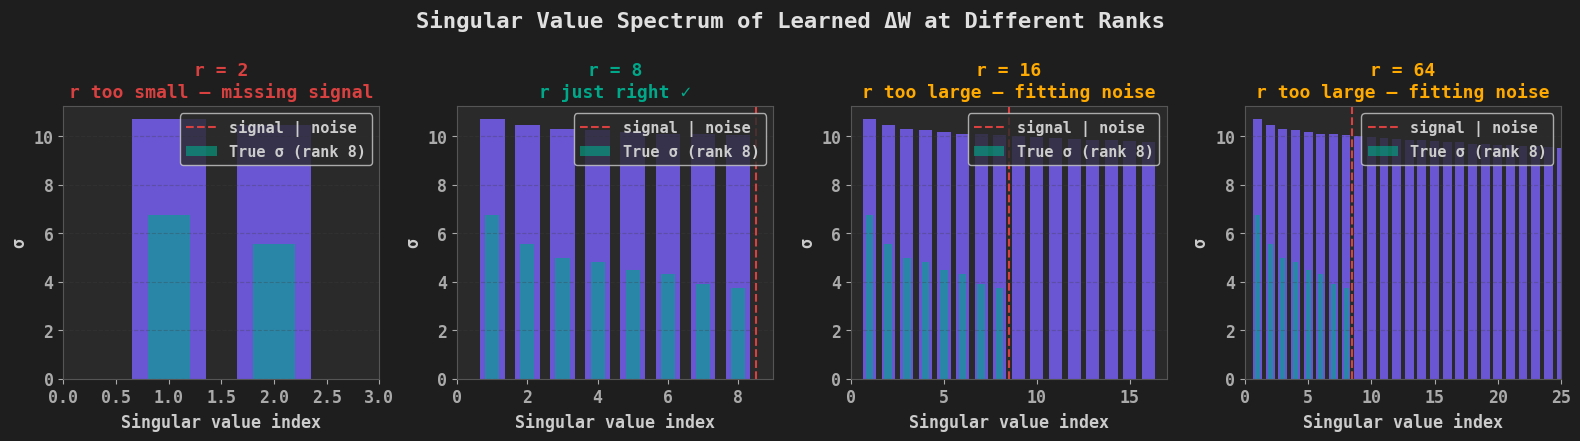

Diagnostic: plot the σ of your learned ΔW.
If values drop sharply after index r* → r* is your optimal rank.
Flat spectrum → r is too large (fitting noise). Abrupt cutoff → too small.


In [11]:
# Simulate learned ΔW at different ranks and inspect its SVD
# Signal source: a real DistilBERT attention weight matrix (different from W0 used in Section 3)
_, W_source = list(weight_matrices.items())[1]
d, k = W_source.shape

# Truncate to a low-rank signal — this defines the "true" update we are trying to recover.
# Edit r_signal to explore: does r_signal=4, 16, or 32 change the picture?
r_signal = 8
U_src, s_src, Vt_src = np.linalg.svd(W_source, full_matrices=False)
W_delta_true = (U_src[:, :r_signal] * s_src[:r_signal]) @ Vt_src[:r_signal, :]

# Noise floor: 5% of the weakest signal singular value — clearly sub-signal
noise_scale = 0.05 * s_src[r_signal - 1]
np.random.seed(0)
W_noisy = W_delta_true + noise_scale * np.random.randn(d, k)

# Derive true rank from the clean matrix — no hardcoding
_, s_true_full, _ = np.linalg.svd(W_delta_true, full_matrices=False)
r_true = int(np.sum(s_true_full > 1e-6))   # count numerically non-zero singular values
s_true = s_true_full[:r_true]
print(f"Signal source: real DistilBERT weight matrix, shape {W_source.shape}, truncated to r={r_signal}")
print(f"True rank confirmed by SVD of clean signal: r_true = {r_true}")
print(f"Top {r_true} singular values of clean signal: {np.round(s_true, 3)}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
fig.suptitle("Singular Value Spectrum of Learned ΔW at Different Ranks",
             color=BLACK, fontsize=16, fontweight='bold')

# Panels: too small, just right, slightly over, far over — relative to r_true
ranks_to_test = [max(1, r_true // 4), r_true, r_true * 2, r_true * 8]

for ax, r in zip(axes, ranks_to_test):
    # Project W_noisy onto rank-r subspace (simulates what LoRA would learn)
    U_, s_, Vt_ = np.linalg.svd(W_noisy, full_matrices=False)
    A = np.diag(s_[:r]**0.5) @ Vt_[:r, :]   # r × k
    B = U_[:, :r] * s_[:r]**0.5             # d × r
    delta_W = B @ A

    # SVD of the learned delta_W
    _, s_learned, _ = np.linalg.svd(delta_W, full_matrices=False)

    n_true = min(r_true, r)   # number of "true" bars that fit in this rank

    # Clip x-axis to 3× the true rank — keeps the signal region readable
    # even when r is large (e.g. r=64 with r_true=8 would otherwise squash bars)
    x_show = min(r, r_true * 3)

    ax.bar(range(1, r + 1), s_learned[:r], color=PURPLE, alpha=0.8, width=0.7)
    ax.bar(range(1, n_true + 1), s_true[:n_true],
           color=TEAL, alpha=0.6, width=0.4, label=f"True σ (rank {r_true})")

    # Vertical line marks the signal / noise boundary — bars to the right are noise
    ax.axvline(r_true + 0.5, color=CORAL, lw=1.5, linestyle='--',
               label="signal | noise")

    # Colour-code based on whether rank is appropriate
    if r < r_true:
        status, col = "r too small — missing signal", CORAL
    elif r == r_true:
        status, col = "r just right ✓", TEAL
    else:
        status, col = "r too large — fitting noise", AMBER

    ax.set_title(f"r = {r}\n{status}", fontsize=13, fontweight='bold', color=col)
    ax.set_xlabel("Singular value index", fontsize=12)
    ax.set_ylabel("σ", fontsize=12)
    ax.set_xlim(0, x_show + 1)   # focus on the informative region
    ax.legend(fontsize=11, loc='upper right')
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()
print("Diagnostic: plot the σ of your learned ΔW.")
print("If values drop sharply after index r* → r* is your optimal rank.")
print("Flat spectrum → r is too large (fitting noise). Abrupt cutoff → too small.")


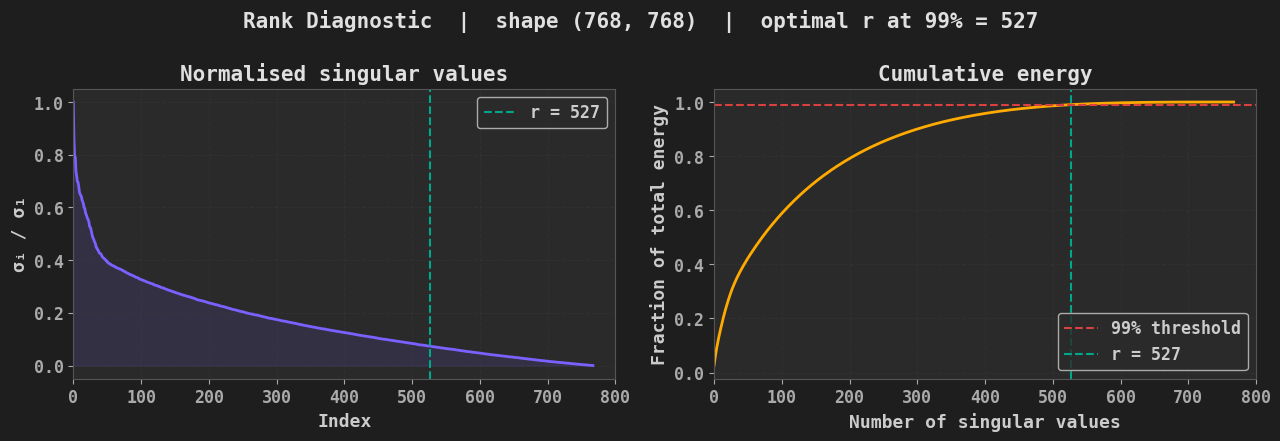


Optimal rank for 99% energy: r = 527
Full rank: 768
Parameter reduction if using LoRA with this r: 0.7x

⚠  Notice: r_opt ≈ 527 is large — barely any parameter saving (0.7x).
   This is intentional and reveals a key insight:
   r_opt here answers 'how many σ to reconstruct W₀ itself' — a high bar.
   LoRA does NOT use this r. It uses r=8 because the fine-tuning
   update ΔW is empirically low-rank, even when W₀ is not.
   The energy spectrum of W₀ motivates the design; it does not set r.


In [12]:
# The elbow finder — practical utility function
def find_optimal_rank(W, energy_threshold=0.99, plot=True):
    """
    Given a weight matrix W, find the rank r that captures
    `energy_threshold` fraction of the Frobenius energy.

    Parameters
    ----------
    W                : np.ndarray — weight matrix
    energy_threshold : float in (0, 1)
    plot             : bool

    Returns
    -------
    r_optimal : int
    """
    U_, s_, Vt_ = np.linalg.svd(W, full_matrices=False)
    energy = np.cumsum(s_**2) / np.sum(s_**2)
    r_optimal = int(np.searchsorted(energy, energy_threshold)) + 1

    if plot:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
        fig.suptitle(f"Rank Diagnostic  |  shape {W.shape}  |  "
                     f"optimal r at {energy_threshold*100:.0f}% = {r_optimal}",
                     color=BLACK, fontsize=15, fontweight='bold')

        # Singular value decay
        ax1.plot(s_ / s_[0], color=PURPLE, lw=2)
        ax1.fill_between(range(len(s_)), s_ / s_[0], alpha=0.12, color=PURPLE)
        ax1.axvline(r_optimal, color=TEAL, lw=1.5, linestyle='--',
                    label=f"r = {r_optimal}")
        ax1.set_title("Normalised singular values", color=BLACK)
        ax1.set_xlabel("Index"); ax1.set_ylabel("σᵢ / σ₁")
        ax1.legend(); ax1.grid(True, alpha=0.3)
        ax1.set_xlim(0, 800)

        # Cumulative energy
        ax2.plot(energy, color=AMBER, lw=2)
        ax2.axhline(energy_threshold, color=CORAL, lw=1.5, linestyle='--',
                    label=f"{energy_threshold*100:.0f}% threshold")
        ax2.axvline(r_optimal, color=TEAL, lw=1.5, linestyle='--',
                    label=f"r = {r_optimal}")
        ax2.set_title("Cumulative energy", color=BLACK)
        ax2.set_xlabel("Number of singular values")
        ax2.set_ylabel("Fraction of total energy")
        ax2.legend(); ax2.grid(True, alpha=0.3)
        ax2.set_xlim(0, 800)

        plt.tight_layout()

        plt.show()

    return r_optimal

# Run on the first DistilBERT weight matrix
r_opt = find_optimal_rank(W0, energy_threshold=0.99)
reduction = W0.shape[0]*W0.shape[1] / (W0.shape[0]*r_opt + r_opt*W0.shape[1])

print(f"\nOptimal rank for 99% energy: r = {r_opt}")
print(f"Full rank: {W0.shape[1]}")
print(f"Parameter reduction if using LoRA with this r: {reduction:.1f}x")
print()
if reduction < 2.0:
    print("⚠  Notice: r_opt ≈ {r_opt} is large — barely any parameter saving ({reduction:.1f}x).".format(
          r_opt=r_opt, reduction=reduction))
    print("   This is intentional and reveals a key insight:")
    print("   r_opt here answers 'how many σ to reconstruct W₀ itself' — a high bar.")
    print("   LoRA does NOT use this r. It uses r=8 because the fine-tuning")
    print("   update ΔW is empirically low-rank, even when W₀ is not.")
    print("   The energy spectrum of W₀ motivates the design; it does not set r.")


---
## Section 6 — Putting It All Together

LoRA is not a heuristic. It is SVD applied to the problem of efficient adaptation.  
Every design decision — the rank constraint, the $B=0$ initialisation, the $\alpha/r$ scaling, the merge-at-inference trick — follows directly from the linear algebra developed in Sections 1–5.

**What the code does:**

1. **`LoRALayer` class** — a minimal, self-contained implementation of a LoRA-augmented linear layer in ~30 lines:
   - `__init__`: stores the frozen weight $W$, initialises $A \sim \mathcal{N}(0, 0.01^2)$ and $B = 0$, so $\Delta W = BA = 0$ at step 0 (matching the paper's initialisation).
   - `forward(x)`: computes $h = Wx + (\alpha/r) \cdot B(Ax)$ — the base output plus the scaled low-rank correction.
   - `merge()`: returns $W + (\alpha/r) \cdot BA$ — collapses the adapter into the weight for zero-overhead inference.
   - `singular_value_spectrum()`: runs SVD on $\Delta W$ to expose the learned rank structure.  
   
   Demonstrates the layer on a real DistilBERT weight matrix (768 × 768) at $r=8$, printing parameter counts, output norms, and confirming $\|\Delta W\|_F = 0$ at initialisation.

2. **Synthesis figure** — a 3-panel summary of the full argument:
   - *Panel 1 — σ decay of pretrained W:* the normalised singular value spectrum of a real DistilBERT attention matrix, annotated to show that most "work" lives in a few directions.
   - *Panel 2 — Eckart–Young error curve:* relative Frobenius error vs rank, with $r=8$ marked — showing how little you lose by keeping only 8 directions.
   - *Panel 3 — LoRA parameter count:* full fine-tuning vs LoRA for $d=k=768$, with the saving at $r=8$ annotated, closing the loop from SVD theory to practical efficiency.

**The complete arc:**  
$\sigma$ decay  →  optimal low-rank approximation  →  parameter-efficient fine-tuning.


In [13]:
# End-to-end: frozen W + LoRA forward pass
import numpy as np

class LoRALayer:
    """
    A single linear layer with a frozen weight matrix W
    and a trainable low-rank update ΔW = B @ A.

    This is the core of PEFT / HuggingFace LoRA in ~30 lines.
    """
    def __init__(self, W_pretrained: np.ndarray, rank: int, alpha: float = 1.0):
        self.W  = W_pretrained          # frozen — never updated
        self.d, self.k = W_pretrained.shape
        self.r  = rank
        self.alpha = alpha              # scaling factor (LoRA paper §4)

        # Initialise A ~ N(0, σ²),  B = 0  →  ΔW = 0 at step 0
        self.A  = np.random.randn(rank, self.k) * 0.01
        self.B  = np.zeros((self.d, rank))

    def forward(self, x: np.ndarray) -> np.ndarray:
        """h = Wx + (α/r) · BAx"""
        base_out  = self.W @ x
        lora_out  = (self.alpha / self.r) * self.B @ (self.A @ x)
        return base_out + lora_out

    @property
    def delta_W(self) -> np.ndarray:
        """The current low-rank update matrix ΔW = BA."""
        return self.B @ self.A

    @property
    def trainable_params(self) -> int:
        return self.d * self.r + self.r * self.k

    @property
    def total_params(self) -> int:
        return self.d * self.k

    def merge(self) -> np.ndarray:
        """Collapse LoRA into W for zero-overhead inference."""
        return self.W + (self.alpha / self.r) * self.delta_W

    def singular_value_spectrum(self):
        """SVD of the learned update ΔW."""
        return np.linalg.svd(self.delta_W, compute_uv=False)


# Instantiate and demonstrate
np.random.seed(7)
d, k = 768, 768
W_pretrained = list(weight_matrices.values())[0]   # real DistilBERT weights
W = W_pretrained

layer_full = W                              # full fine-tune would update this
layer_lora = LoRALayer(W, rank=8, alpha=8)

x = np.random.randn(k)   # a single input vector

out_base = layer_full @ x
out_lora = layer_lora.forward(x)

print("=" * 55)
print("  LoRALayer demonstration")
print("=" * 55)
print(f"  Weight matrix shape       : {W.shape}")
print(f"  Rank r                    : {layer_lora.r}")
print(f"  Trainable params (A + B)  : {layer_lora.trainable_params:,}")
print(f"  Frozen params (W)         : {layer_lora.total_params:,}")
print(f"  Reduction factor          : {layer_lora.total_params / layer_lora.trainable_params:.1f}x")
print()
print(f"  ‖output_base‖             : {np.linalg.norm(out_base):.4f}")
print(f"  ‖output_lora‖             : {np.linalg.norm(out_lora):.4f}")
print(f"  ‖ΔW = BA‖_F (init=0)     : {np.linalg.norm(layer_lora.delta_W, 'fro'):.6f}")
print()
W_merged = layer_lora.merge()
print(f"  After merge: ‖W_merged - W‖_F = {np.linalg.norm(W_merged - W, 'fro'):.6f}")
print("  (zero at init — would grow during training)")


  LoRALayer demonstration
  Weight matrix shape       : (768, 768)
  Rank r                    : 8
  Trainable params (A + B)  : 12,288
  Frozen params (W)         : 589,824
  Reduction factor          : 48.0x

  ‖output_base‖             : 36.4533
  ‖output_lora‖             : 36.4533
  ‖ΔW = BA‖_F (init=0)     : 0.000000

  After merge: ‖W_merged - W‖_F = 0.000000
  (zero at init — would grow during training)


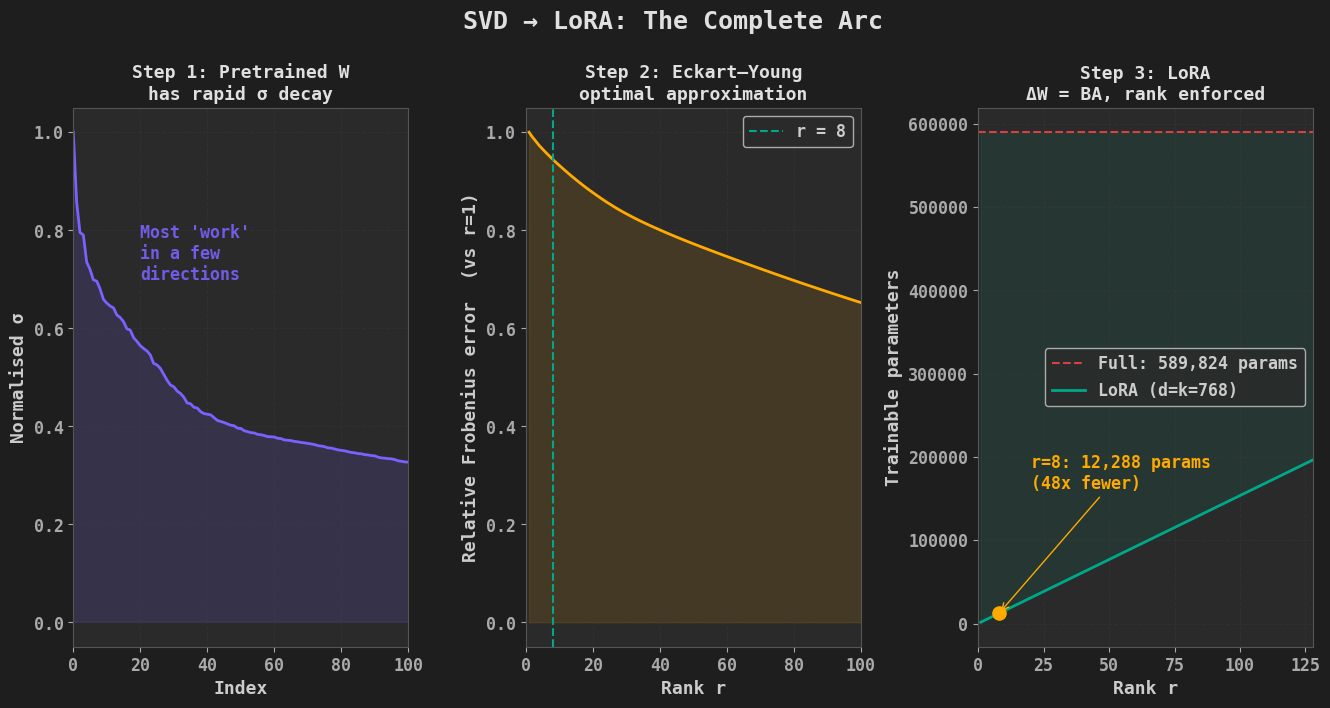

Three panels. One story.
σ decay  →  optimal low-rank approx  →  parameter-efficient fine-tuning.


In [14]:
# Final synthesis plot
# Shows the full SVD → LoRA connection in one figure

fig = plt.figure(figsize=(16, 7))
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.35)

# Panel 1: Singular value spectrum of pretrained W
ax1 = fig.add_subplot(gs[0])
_, s_W, _ = np.linalg.svd(W_pretrained, full_matrices=False)
ax1.plot(s_W / s_W[0], color=PURPLE, lw=2)
ax1.fill_between(range(len(s_W)), s_W / s_W[0], alpha=0.15, color=PURPLE)
ax1.set_title("Step 1: Pretrained W\nhas rapid σ decay", color=BLACK, fontsize=13, fontweight='bold')
ax1.set_xlabel("Index"); ax1.set_ylabel("Normalised σ")
ax1.set_xlim(0, 100); ax1.grid(True, alpha=0.3)
ax1.text(20, 0.7, "Most 'work'\nin a few\ndirections",
         color=PURPLE, fontsize=12, fontweight='bold', alpha=0.9)

# Panel 2: Low-rank approximation error
ax2 = fig.add_subplot(gs[1])
r_range2 = np.arange(1, 101)
errs = [np.linalg.norm(W_pretrained -
        (U0[:, :r] * s0[:r]) @ Vt0[:r, :], 'fro') for r in r_range2]
errs_rel = np.array(errs) / errs[0]
ax2.plot(r_range2, errs_rel, color=AMBER, lw=2)
ax2.fill_between(r_range2, errs_rel, alpha=0.12, color=AMBER)
ax2.axvline(8, color=TEAL, lw=1.5, linestyle='--', label="r = 8")
ax2.set_title("Step 2: Eckart–Young\noptimal approximation", color=BLACK, fontsize=13, fontweight='bold')
ax2.set_xlabel("Rank r"); ax2.set_ylabel("Relative Frobenius error  (vs r=1)")
ax2.set_xlim(0, 100); ax2.legend(fontsize=12); ax2.grid(True, alpha=0.3)

# Panel 3: LoRA parameterisation
ax3 = fig.add_subplot(gs[2])
r_vals3 = np.arange(1, 129)
lora_p = d * r_vals3 + r_vals3 * k
full_p  = d * k
ax3.axhline(full_p, color=CORAL, lw=1.5, linestyle='--',
            label=f"Full: {full_p:,} params")
ax3.plot(r_vals3, lora_p, color=TEAL, lw=2,
         label="LoRA (d=k=768)")
ax3.fill_between(r_vals3, lora_p, full_p, alpha=0.1, color=TEAL)
ax3.scatter([8], [d * 8 + 8 * k], s=90, color=AMBER, zorder=5)
ax3.annotate(f"r=8: {d*8+8*k:,} params\n({full_p/(d*8+8*k):.0f}x fewer)",
             xy=(8, d*8+8*k), xytext=(20, d*8+8*k + 150000),
             color=AMBER, fontsize=12, fontweight='bold',
             arrowprops=dict(arrowstyle='->', color=AMBER, lw=1))
ax3.set_title("Step 3: LoRA\nΔW = BA, rank enforced", color=BLACK, fontsize=13, fontweight='bold')
ax3.set_xlabel("Rank r"); ax3.set_ylabel("Trainable parameters")
ax3.set_xlim(0, 128); ax3.legend(fontsize=12); ax3.grid(True, alpha=0.3)

fig.suptitle("SVD → LoRA: The Complete Arc",
             fontsize=18, color=BLACK, y=1.02, fontweight='bold')
plt.show()
print("Three panels. One story.")
print("σ decay  →  optimal low-rank approx  →  parameter-efficient fine-tuning.")


---

## Summary

| Concept | Key result |
|---|---|
| SVD: $M = U\Sigma V^\top$ | Every matrix = rotate · scale · rotate |
| Singular value decay | Trained weights are intrinsically low-rank |
| Eckart–Young theorem | Rank-r truncated SVD is the *optimal* approximation |
| LoRA: $\Delta W = BA$ | Enforces low rank; $r \ll d,k$ → orders of magnitude fewer params |
| Choosing $r$ | Find the elbow in the σ spectrum of your update |

---